In [7]:
import json
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

RUTA_PROYECTO = Path("..")

RUTA_NAIVE_BAYES = (
    RUTA_PROYECTO
    / "models"
    / "primera_iteracion"
    / "naive_bayes"
)

RUTA_REGRESION_LOGISTICA = (
    RUTA_PROYECTO
    / "models"
    / "primera_iteracion"
    / "regresion_logistica"
)

RUTA_EVALUACION = (
    RUTA_PROYECTO
    / "models"
    / "primera_iteracion"
    / "evaluacion"
)

RUTA_EVALUACION.mkdir(
    parents=True,
    exist_ok=True
)

In [8]:
with open(
    RUTA_NAIVE_BAYES / "metricas_naive_bayes.json",
    "r",
    encoding="utf-8"
) as archivo:
    metricas_nb = json.load(archivo)

with open(
    RUTA_REGRESION_LOGISTICA
    / "metricas_regresion_logistica.json",
    "r",
    encoding="utf-8"
) as archivo:
    metricas_rl = json.load(archivo)

In [9]:
print("MÉTRICAS DE NAIVE BAYES")
print(metricas_nb)

print("\nMÉTRICAS DE REGRESIÓN LOGÍSTICA")
print(metricas_rl)

MÉTRICAS DE NAIVE BAYES
{'modelo': 'Multinomial Naive Bayes', 'accuracy': 0.8521892220325917, 'precision_macro': 0.6714923818100731, 'recall_macro': 0.6195865376276871, 'f1_macro': 0.6383261276371305, 'tiempo_entrenamiento_segundos': 3.9723013999755494, 'tiempo_prediccion_segundos': 0.10868900001514703, 'numero_resenas_entrenamiento': 1188274, 'numero_resenas_prueba': 297069, 'numero_caracteristicas': 50000, 'alpha': 1.0, 'convergencia_alcanzada': None}

MÉTRICAS DE REGRESIÓN LOGÍSTICA
{'modelo': 'Regresión Logística', 'accuracy': 0.8889483587987976, 'precision_macro': 0.7478088497015078, 'recall_macro': 0.6755552591420929, 'f1_macro': 0.6942251483589432, 'tiempo_entrenamiento_segundos': 2291.2168070000043, 'tiempo_prediccion_segundos': 0.11343860000488348, 'iteraciones_realizadas': 1000, 'max_iter': 1000, 'convergencia_alcanzada': False, 'solver': 'saga', 'C': 1.0, 'tolerancia': 0.0001, 'numero_resenas_entrenamiento': 1188274, 'numero_resenas_prueba': 297069, 'numero_caracteristicas':

In [16]:
# Comparación

comparacion_modelos = pd.DataFrame([
    {
        "Modelo": "Multinomial Naive Bayes",
        "Accuracy": metricas_nb["accuracy"],
        "Precision macro": metricas_nb["precision_macro"],
        "Recall macro": metricas_nb["recall_macro"],
        "F1 macro": metricas_nb["f1_macro"],
        "Tiempo entrenamiento": (
            metricas_nb["tiempo_entrenamiento_segundos"]
        ),
        "Tiempo predicción": (
            metricas_nb["tiempo_prediccion_segundos"]
        ),
        "Convergencia": "No aplica"
    },
    {
        "Modelo": "Regresión Logística",
        "Accuracy": metricas_rl["accuracy"],
        "Precision macro": metricas_rl["precision_macro"],
        "Recall macro": metricas_rl["recall_macro"],
        "F1 macro": metricas_rl["f1_macro"],
        "Tiempo entrenamiento": (
            metricas_rl["tiempo_entrenamiento_segundos"]
        ),
        "Tiempo predicción": (
            metricas_rl["tiempo_prediccion_segundos"]
        ),
        "Convergencia": (
            metricas_rl["convergencia_alcanzada"]
        )
    }
])

comparacion_modelos.round(4)

,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,Tiempo entrenamiento,Tiempo predicción,Convergencia
0,Multinomial Naive Bayes,0.8522,0.6715,0.6196,0.6383,3.9723,0.1087,No aplica
1,Regresión Logística,0.8889,0.7478,0.6756,0.6942,2291.2168,0.1134,False


In [17]:
# Modelo base
modelo_base = {
    "Modelo": "Clase mayoritaria",
    "Accuracy": 0.7601,
    "Precision macro": 0.2534,
    "Recall macro": 0.3333,
    "F1 macro": 0.2879,
    "Tiempo entrenamiento": 0.0,
    "Tiempo predicción": 0.0,
    "Convergencia": "No aplica"
}

comparacion_modelos = pd.concat(
    [
        pd.DataFrame([modelo_base]),
        comparacion_modelos
    ],
    ignore_index=True
)

comparacion_modelos.round(4)

,Modelo,Accuracy,Precision macro,Recall macro,F1 macro,Tiempo entrenamiento,Tiempo predicción,Convergencia
0,Clase mayoritaria,0.7601,0.2534,0.3333,0.2879,0.0000,0.0000,No aplica
1,Multinomial Naive Bayes,0.8522,0.6715,0.6196,0.6383,3.9723,0.1087,No aplica
2,Regresión Logística,0.8889,0.7478,0.6756,0.6942,2291.2168,0.1134,False


In [18]:
mejor_modelo = comparacion_modelos.loc[
    comparacion_modelos["F1 macro"].idxmax()
]

print("MEJOR MODELO DE LA PRIMERA ITERACIÓN")
print("------------------------------------")
print(
    "Modelo:",
    mejor_modelo["Modelo"]
)
print(
    "Accuracy:",
    f"{mejor_modelo['Accuracy']:.4f}"
)
print(
    "F1 macro:",
    f"{mejor_modelo['F1 macro']:.4f}"
)

MEJOR MODELO DE LA PRIMERA ITERACIÓN
------------------------------------
Modelo: Regresión Logística
Accuracy: 0.8889
F1 macro: 0.6942


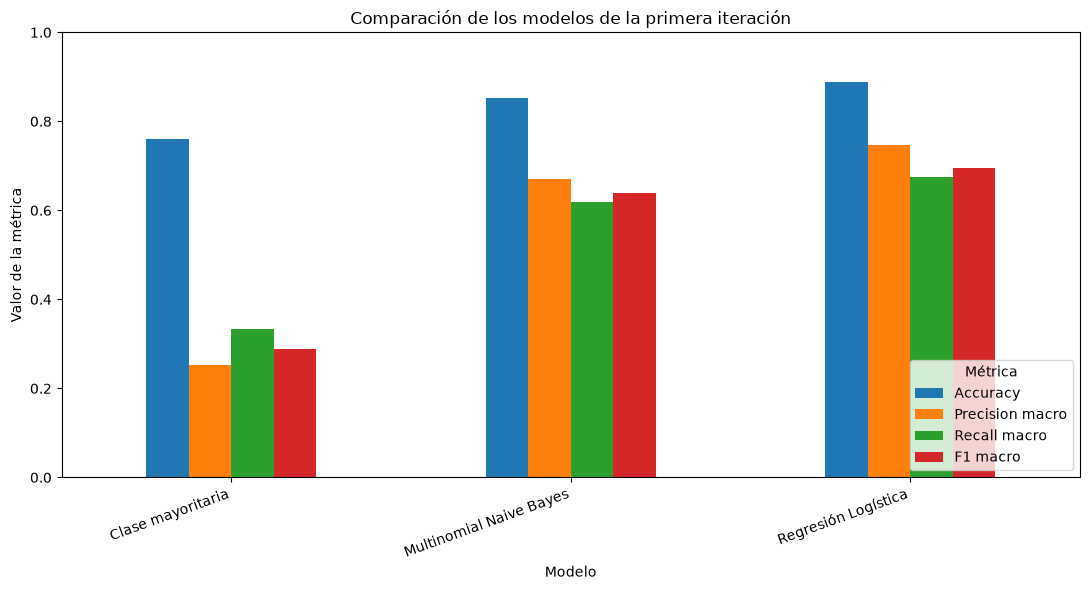

In [19]:
# Representación de métricas
metricas_grafica = comparacion_modelos.set_index(
    "Modelo"
)[
    [
        "Accuracy",
        "Precision macro",
        "Recall macro",
        "F1 macro"
    ]
]

metricas_grafica.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title(
    "Comparación de los modelos de la primera iteración"
)

plt.xlabel("Modelo")
plt.ylabel("Valor de la métrica")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(
    title="Métrica",
    loc="lower right"
)
plt.tight_layout()
plt.show()

In [20]:
# Guardar gráfica
figura = metricas_grafica.plot(
    kind="bar",
    figsize=(11, 6)
).get_figure()

plt.title(
    "Comparación de los modelos de la primera iteración"
)

plt.xlabel("Modelo")
plt.ylabel("Valor de la métrica")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(
    title="Métrica",
    loc="lower right"
)
plt.tight_layout()

figura.savefig(
    RUTA_EVALUACION
    / "comparacion_modelos_primera_iteracion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close(figura)

In [21]:
tiempos_modelos = comparacion_modelos[
    comparacion_modelos["Modelo"]
    != "Clase mayoritaria"
].set_index("Modelo")[
    [
        "Tiempo entrenamiento",
        "Tiempo predicción"
    ]
]

tiempos_modelos

,Tiempo entrenamiento,Tiempo predicción
Modelo,,
Multinomial Naive Bayes,3.972301,0.108689
Regresión Logística,2291.216807,0.113439


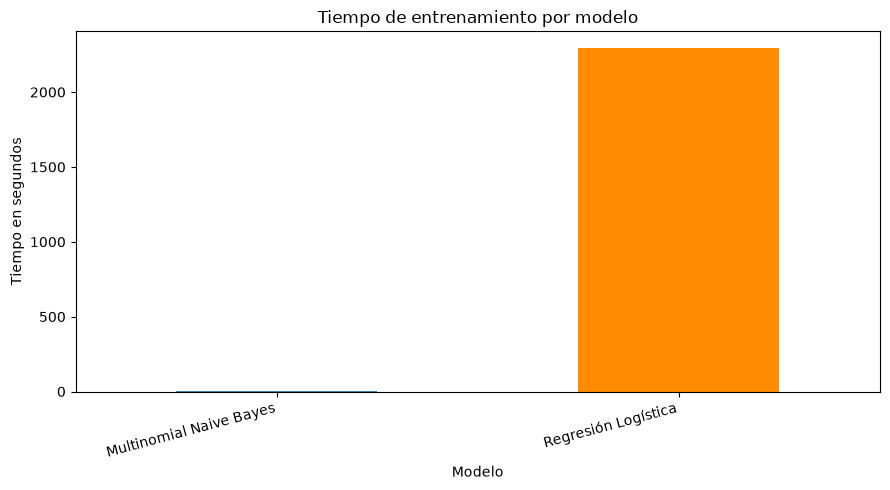

In [22]:
# Gráfica de entrenamiento

eje = tiempos_modelos[
    "Tiempo entrenamiento"
].plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "darkorange"]
)

plt.title("Tiempo de entrenamiento por modelo")
plt.xlabel("Modelo")
plt.ylabel("Tiempo en segundos")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()

figura_tiempos = eje.get_figure()

figura_tiempos.savefig(
    RUTA_EVALUACION
    / "tiempos_entrenamiento_primera_iteracion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
# Guardar comparación

comparacion_modelos.to_csv(
    RUTA_EVALUACION
    / "comparacion_modelos_primera_iteracion.csv",
    index=False
)

print(
    "Comparación guardada en:",
    RUTA_EVALUACION.resolve()
)

Comparación guardada en: C:\Users\Paula María\Desktop\IS\5º CURSO\TFG\Trabajo-Fin-de-Grado\models\primera_iteracion\evaluacion


In [24]:
# Comparación métricas por clase

informe_nb = pd.read_csv(
    RUTA_NAIVE_BAYES
    / "informe_clasificacion_naive_bayes.csv",
    index_col=0
)

informe_rl = pd.read_csv(
    RUTA_REGRESION_LOGISTICA
    / "informe_clasificacion_regresion_logistica.csv",
    index_col=0
)

In [25]:
comparacion_por_clase = pd.DataFrame({
    "Clase": [
        "negativo",
        "neutral",
        "positivo"
    ],
    "F1 Naive Bayes": [
        informe_nb.loc["negativo", "f1-score"],
        informe_nb.loc["neutral", "f1-score"],
        informe_nb.loc["positivo", "f1-score"]
    ],
    "F1 Regresión Logística": [
        informe_rl.loc["negativo", "f1-score"],
        informe_rl.loc["neutral", "f1-score"],
        informe_rl.loc["positivo", "f1-score"]
    ]
})

comparacion_por_clase.round(4)

,Clase,F1 Naive Bayes,F1 Regresión Logística
0,negativo,0.7385,0.8114
1,neutral,0.2542,0.3244
2,positivo,0.9223,0.9469


In [26]:
# Guardar tabla
comparacion_por_clase.to_csv(
    RUTA_EVALUACION
    / "comparacion_f1_por_clase.csv",
    index=False
)